# Uji Titik Start Rute Lari

Alur: **isi latitude/longitude → unduh graf → periksa marker → training → lihat hasil**.

Notebook memakai core bersama dengan tiga training dengan seed acak berbeda. Semua percobaan memakai
folder `uji_titik_start/terbaru/` yang sama dan hasilnya selalu ditimpa.
Graf dan eksperimen utama A–C tetap terpisah.

- Jalankan cell unduh: selalu mengambil data OSM baru tanpa cache, mengganti graf
  dan menghapus hasil training dari graf sebelumnya.
- Jalankan cell training lagi: memakai graf yang sudah diunduh dalam memori,
  melatih dari Q-table kosong, dan hanya mengganti folder hasil training.
- Ganti koordinat: jalankan ulang cell unduh, peta, konfigurasi, training dan hasil.

Gunakan kernel **TA Rute Lari (Python 3.13)**. Unduhan memerlukan internet.

Reward memakai rancangan langsung H/S/W +1/-1/0 dari core, tanpa pengurangan 0,50.
Highway satu prioritas termasuk tertiary; mean_comfort berskala -1..1.


In [73]:
import importlib
import json
import math
import hashlib
import shutil
import secrets
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from html import escape

import folium
import osmnx as ox
import pandas as pd
from pyproj import Transformer
from IPython.display import display, HTML
import rute_lari_core as core

importlib.reload(core)
print("Core:", core.__file__)
print("Mode uji: tiga training; seed acak berbeda dibuat saat training dimulai.")

Core: /Users/david/widya_kartika/uwika-ta-31123022-2026/rute_lari_core.py
Mode uji: tiga training; seed acak berbeda dibuat saat training dimulai.


## 1. Isi koordinat lokasi

Ganti `SEARCH_LAT` dan `SEARCH_LON`. Tidak perlu mengganti nama titik atau run.
Cell unduh selalu mengambil graf baru, meskipun koordinatnya tetap sama.
Radius bbox default mengikuti penelitian; `MAX_SNAP_DISTANCE_M` membatasi
pergeseran dari input ke node sebelum training.


In [74]:
SEARCH_LAT = -7.281521
SEARCH_LON = 112.710178
DOWNLOAD_RADIUS_M = core.DOWNLOAD_RADIUS_M
MAX_SNAP_DISTANCE_M = 100.0


## 2. Unduh graf dan cari node start

Setiap eksekusi selalu mengunduh graf jalan kaki di sekitar koordinat saat ini,
melewati GraphML lama dan cache HTTP. Graf diproyeksikan ke meter dan mengganti
`uji_titik_start/terbaru/graf_jalan_kaki.graphml`.

Setelah unduhan berhasil, hasil training sebelumnya pada folder `training/`
dihapus agar tidak ditampilkan sebagai hasil untuk graf baru. Jalankan cell peta
berikutnya untuk memperbarui marker. Jika hanya ingin mengulang training dengan
peta yang sama, langsung jalankan cell training; tidak perlu mengunduh ulang.


In [75]:
# Batalkan konteks lama lebih dahulu agar unduhan gagal tidak memakai peta lama.
SEARCH_CONTEXT = PREVIEW_CONTEXT = CONFIG_CONTEXT = TRAINING_CONTEXT = None
latitude, longitude = float(SEARCH_LAT), float(SEARCH_LON)
if not (math.isfinite(latitude) and math.isfinite(longitude)
        and -90 <= latitude <= 90 and -180 <= longitude <= 180):
    raise ValueError("Latitude/longitude tidak valid. Periksa urutan dan nilainya.")
GRAPH_SUBDIR = "uji_titik_start/terbaru"
POINT_DIR = core.RESULT_DIR / GRAPH_SUBDIR
GRAPH_PATH = POINT_DIR / "graf_jalan_kaki.graphml"
GRAPH_METADATA_PATH = POINT_DIR / "metadata_graf.json"

G, START_NODE, GRAPH_PATH, downloaded_now = core.load_or_download_graph(
    force_download=True,
    center_point=(latitude, longitude), graph_path=GRAPH_PATH,
    download_radius_m=DOWNLOAD_RADIUS_M, use_cache=False,
)
graph_metadata = {
    "downloaded_at": datetime.now(ZoneInfo("Asia/Jakarta")).isoformat(),
    "requested_lat": latitude, "requested_lon": longitude,
    "radius_m": DOWNLOAD_RADIUS_M, "dist_type": "bbox", "network_type": "walk",
    "http_cache_used": False,
    "graph_sha256": hashlib.sha256(GRAPH_PATH.read_bytes()).hexdigest(),
}
GRAPH_METADATA_PATH.write_text(json.dumps(graph_metadata, indent=2), encoding="utf-8")
core.add_comfort_scores(G)
NODE_XY = {int(node): (float(data["x"]), float(data["y"]))
           for node, data in G.nodes(data=True)}
to_graph = Transformer.from_crs("EPSG:4326", G.graph["crs"], always_xy=True)
to_wgs84 = Transformer.from_crs(G.graph["crs"], "EPSG:4326", always_xy=True)
search_x, search_y = to_graph.transform(longitude, latitude)
SNAP_DISTANCE_M = math.hypot(search_x - NODE_XY[START_NODE][0], search_y - NODE_XY[START_NODE][1])
START_NODE_LAT, START_NODE_LON = core.node_latlon(START_NODE, NODE_XY, to_wgs84)
ACTIONS_BY_NODE = core.build_actions(G)
initial_environment = core.RunningRouteEnvironment(START_NODE, "B", ACTIONS_BY_NODE, NODE_XY)
INITIAL_ACTIONS = initial_environment.available_actions()

# Hanya hasil uji terbaru dibuang. Graf utama dan eksperimen A–C tidak disentuh.
training_dir = core.RESULT_DIR / "uji_titik_start/terbaru/training"
if training_dir.exists():
    shutil.rmtree(training_dir)
(POINT_DIR / "peta_titik_start.html").unlink(missing_ok=True)
SEARCH_CONTEXT = (latitude, longitude, DOWNLOAD_RADIUS_M, START_NODE,
                  str(GRAPH_PATH), graph_metadata["graph_sha256"])

display(pd.DataFrame([{
    "latitude_input": latitude, "longitude_input": longitude, "start_node": START_NODE,
    "latitude_node": START_NODE_LAT, "longitude_node": START_NODE_LON,
    "jarak_input_ke_node_m": SNAP_DISTANCE_M,
    "jumlah_node": len(G), "jumlah_edge": G.number_of_edges(),
    "jumlah_action_awal_legal": len(INITIAL_ACTIONS),
}]))
print("Sumber: unduhan OSM baru (tanpa cache HTTP)")
print("Graf ditimpa:", GRAPH_PATH)
print("Jalankan cell peta untuk memperbarui marker START.")
if SNAP_DISTANCE_M > MAX_SNAP_DISTANCE_M:
    print("Node cukup jauh dari koordinat masukan. Periksa peta sebelum training.")
if not INITIAL_ACTIONS:
    print("Node ini tidak memiliki action awal legal setelah aturan akses/mask.")


,latitude_input,longitude_input,start_node,latitude_node,longitude_node,jarak_input_ke_node_m,jumlah_node,jumlah_edge,jumlah_action_awal_legal
0,-7.281521,112.710178,311432306,-7.281525,112.710187,1.126505,8284,22136,4


Sumber: unduhan OSM baru (tanpa cache HTTP)
Graf ditimpa: /Users/david/widya_kartika/uwika-ta-31123022-2026/hasil_bab_4/training_qlearning_5km/uji_titik_start/terbaru/graf_jalan_kaki.graphml
Jalankan cell peta untuk memperbarui marker START.


## 3. Peta Interaktif Atribut Jalan dan Akses

Peta memakai graf yang baru diunduh, tanpa unduhan tambahan pada cell ini.

- **Highway** aktif secara default; pilih **Surface** untuk mengganti warna ruas.
- Centang **Marker access=...** untuk menampilkan titik tengah ruas menurut jenis
  akses. Marker akses awalnya tidak aktif. Legenda mengikuti layer yang dipilih.
- **Biru:** koordinat masukan; **START hijau:** node awal/akhir agen. Garis putus-putus
  menunjukkan pergeseran input ke node. Overlay **Ruas awal legal** dapat diaktifkan.
- Tooltip memuat highway, surface, width, access, panjang dan reward dasar ruas.
- Seluruh ruas ditampilkan, termasuk access yang ditolak whitelist, untuk inspeksi.
  Marker access bukan lokasi pasti pagar. Tidak ada layer smoothness.

Cell ini menimpa peta_titik_start.html. Setelah mengganti koordinat, ulangi unduhan
lalu cell peta. Training ulang tetap memakai G dalam memori tanpa unduhan graf.


In [76]:
if SEARCH_CONTEXT is None or (float(SEARCH_LAT), float(SEARCH_LON), DOWNLOAD_RADIUS_M) != SEARCH_CONTEXT[:3]:
    raise RuntimeError("Jalankan cell unduh untuk koordinat dan radius saat ini terlebih dahulu.")

from branca.element import MacroElement, Template

# Seluruh graf ditampilkan untuk inspeksi, termasuk ruas di luar whitelist access.
# Data peta berasal dari G yang sudah diunduh; tidak ada permintaan graf baru.
core.add_comfort_scores(G)
preview_edges = ox.graph_to_gdfs(G, nodes=False, edges=True, fill_edge_geometry=True).reset_index()
for attribute in ("name", "highway", "surface", "width", "access", "osmid"):
    if attribute not in preview_edges:
        preview_edges[attribute] = None

PREVIEW_HIGHWAY_COLORS = {
    "residential": "#2563EB", "living_street": "#16A34A", "service": "#6B7280",
    "secondary": "#F97316", "secondary_link": "#F97316", "tertiary": "#EAB308",
    "tertiary_link": "#EAB308", "primary": "#DC2626", "primary_link": "#DC2626",
    "trunk": "#7C3AED", "footway": "#DB2777", "pedestrian": "#DB2777",
    "path": "#14B8A6", "unclassified": "#92400E", "track": "#65A30D",
    "gabungan": "#475569", "lainnya": "#64748B", "tidak_terisi": "#9CA3AF",
}
PREVIEW_SURFACE_COLORS = {
    "asphalt": "#2563EB", "concrete": "#F97316", "paving_stones": "#16A34A",
    "paved": "#06B6D4", "sett": "#D97706", "compacted": "#84CC16",
    "fine_gravel": "#EAB308", "gravel": "#92400E", "dirt": "#DC2626",
    "ground": "#A16207", "unpaved": "#7C3AED", "gabungan": "#DB2777",
    "lainnya": "#475569", "tidak_terisi": "#9CA3AF",
}
PREVIEW_ACCESS_STYLES = {
    "yes": ("green", "check"), "permissive": ("blue", "info-circle"),
    "no": ("red", "ban"), "private": ("darkred", "lock"),
    "destination": ("orange", "flag"),
}

def preview_tokens(value):
    return sorted({part.strip() for item in core.osm_values(value)
                   for part in item.split(";") if part.strip()})

def preview_text(value):
    values = preview_tokens(value)
    return "; ".join(values) if values else "tidak_terisi"

def preview_category(value, colors):
    values = preview_tokens(value)
    if not values:
        return "tidak_terisi"
    if len(values) > 1:
        return "gabungan"
    return values[0] if values[0] in colors else "lainnya"

preview_edges["highway_category"] = preview_edges["highway"].apply(
    lambda value: preview_category(value, PREVIEW_HIGHWAY_COLORS))
preview_edges["surface_category"] = preview_edges["surface"].apply(
    lambda value: preview_category(value, PREVIEW_SURFACE_COLORS))
preview_edges["highway_color"] = preview_edges["highway_category"].map(PREVIEW_HIGHWAY_COLORS)
preview_edges["surface_color"] = preview_edges["surface_category"].map(PREVIEW_SURFACE_COLORS)
for attribute in ("name", "highway", "surface", "width", "access"):
    preview_edges[f"{attribute}_display"] = preview_edges[attribute].apply(
        lambda value: escape(preview_text(value)))
preview_edges["length_m"] = preview_edges["length"].round(1)
preview_wgs84 = preview_edges.to_crs(epsg=4326)

start_map = folium.Map(location=[latitude, longitude], zoom_start=17,
                       tiles=None, control_scale=True)
# Basemap tidak ikut radio layer agar selalu tampil ketika tema ruas diganti.
folium.TileLayer("OpenStreetMap", control=False).add_to(start_map)
preview_highway_layer = folium.FeatureGroup(
    name="Highway (jenis jalan)", overlay=False, show=True).add_to(start_map)
preview_surface_layer = folium.FeatureGroup(
    name="Surface (permukaan jalan)", overlay=False, show=False).add_to(start_map)
preview_fields = ["name_display", "highway_display", "surface_display", "width_display",
                  "access_display", "highway_score", "surface_score", "width_score",
                  "comfort_score", "length_m"]
preview_aliases = ["Nama ruas", "Highway", "Surface", "Width", "Access", "Reward dasar highway",
                   "Reward dasar surface", "Reward dasar width", "Gabungan ruas (-1..1)", "Panjang (m)"]
for layer, color_column in ((preview_highway_layer, "highway_color"),
                            (preview_surface_layer, "surface_color")):
    folium.GeoJson(
        data=preview_wgs84[["u", "v", "key", *preview_fields, color_column, "geometry"]].to_json(),
        style_function=lambda feature, column=color_column: {
            "color": feature["properties"][column], "weight": 3, "opacity": .85},
        tooltip=folium.GeoJsonTooltip(fields=preview_fields, aliases=preview_aliases,
                                     localize=True, sticky=False),
        control=False,
    ).add_to(layer)

# Marker input/start tetap terlihat pada kedua tema, terpisah dari marker akses.
folium.CircleMarker(
    [latitude, longitude], radius=8, color="#2563EB", fill=True, fill_opacity=.9,
    tooltip="Koordinat masukan", popup=f"Input: {latitude:.6f}, {longitude:.6f}",
).add_to(start_map)
folium.Marker(
    [START_NODE_LAT, START_NODE_LON], tooltip=f"START — node {START_NODE}",
    popup=f"<b>START agen</b><br>Node: {START_NODE}<br>Pergeseran dari input: {SNAP_DISTANCE_M:.2f} m",
    icon=folium.Icon(color="green", icon="play", prefix="fa"),
).add_to(start_map)
folium.PolyLine(
    [[latitude, longitude], [START_NODE_LAT, START_NODE_LON]],
    color="#64748B", weight=2, dash_array="5,5",
    tooltip="Pencocokan koordinat ke node, bukan lintasan jalan",
).add_to(start_map)
initial_roads = folium.FeatureGroup(name="Ruas awal legal", show=False).add_to(start_map)
for action in INITIAL_ACTIONS:
    folium.PolyLine(
        core.edge_latlon(START_NODE, action, NODE_XY, to_wgs84), color="#16A34A", weight=5,
        tooltip=f"Ke node {action.next_node} (key={action.key}), {action.length_m:.1f} m; "
                f"access={escape(preview_text(action.data.get('access')))}",
    ).add_to(initial_roads)

# Titik tengah di CRS meter. Dua arah identik berbagi marker; key paralel tetap terpisah.
preview_access_records = {}
for row in preview_edges.itertuples(index=False):
    tokens = preview_tokens(row.access)
    geometry = row.geometry
    if not tokens or geometry is None or geometry.is_empty:
        continue
    label = "; ".join(tokens)
    signature = (tuple(sorted((int(row.u), int(row.v)))), str(row.key),
                 geometry.normalize().wkb_hex, tuple(preview_tokens(row.osmid)), label)
    if signature not in preview_access_records:
        point = geometry.interpolate(.5, normalized=True)
        lon, lat = to_wgs84.transform(point.x, point.y)
        preview_access_records[signature] = {
            "label": label, "location": [lat, lon], "name": preview_text(row.name),
            "osmid": preview_text(row.osmid), "highway": preview_text(row.highway),
            "whitelisted": set(tokens).issubset(core.ACCESS_WHITELIST), "edges": [],
        }
    preview_access_records[signature]["edges"].append((int(row.u), int(row.v), row.key))

preview_access_layers = {}
for record in preview_access_records.values():
    label = record["label"]
    if label not in preview_access_layers:
        preview_access_layers[label] = folium.FeatureGroup(
            name=f"Marker access={label}", show=False).add_to(start_map)
    color, icon = PREVIEW_ACCESS_STYLES.get(label, ("purple", "question"))
    edge_text = "<br>".join(f"{u} → {v} (key={escape(str(key))})" for u, v, key in record["edges"])
    popup = (f"<b>Access: {escape(label)}</b><br>Nama: {escape(record['name'])}<br>"
             f"Highway: {escape(record['highway'])}<br>Way asal: {escape(record['osmid'])}<br>"
             f"Lolos whitelist access: {'ya' if record['whitelisted'] else 'tidak'}<br>"
             f"Edge:<br>{edge_text}<hr>Marker adalah titik tengah ruas, bukan lokasi pasti pagar.")
    folium.Marker(
        record["location"], tooltip=f"access={escape(label)} — {escape(record['name'])}",
        popup=folium.Popup(popup, max_width=380),
        icon=folium.Icon(color=color, icon=icon, prefix="fa"),
    ).add_to(preview_access_layers[label])

folium.LayerControl(collapsed=False).add_to(start_map)

# Legenda mengikuti tema ruas dan marker yang aktif.
preview_legend_style = ("position:fixed;bottom:12px;z-index:9999;max-height:190px;overflow:auto;"
                        "background:rgba(255,255,255,.95);border:1px solid #999;border-radius:6px;"
                        "padding:8px 10px;font:12px Arial,sans-serif;box-shadow:0 1px 4px #999;")
preview_highway_legend_id = f"preview_highway_{start_map.get_name()}"
preview_surface_legend_id = f"preview_surface_{start_map.get_name()}"
preview_access_legend_id = f"preview_access_{start_map.get_name()}"
for legend_id, title, colors, observed, visible in (
    (preview_highway_legend_id, "Jenis Jalan", PREVIEW_HIGHWAY_COLORS,
     set(preview_edges["highway_category"]), True),
    (preview_surface_legend_id, "Surface (material)", PREVIEW_SURFACE_COLORS,
     set(preview_edges["surface_category"]), False),
):
    rows = "".join(f'<div><span style="display:inline-block;width:18px;height:5px;background:{color};'
                   f'margin-right:6px;"></span>{escape(label)}</div>'
                   for label, color in colors.items() if label in observed)
    start_map.get_root().html.add_child(folium.Element(
        f'<div id="{legend_id}" style="{preview_legend_style}left:12px;'
        f'display:{"block" if visible else "none"};"><b>{title}</b>{rows}</div>'))
preview_access_rows = "".join(
    f'<div><i class="fa fa-{PREVIEW_ACCESS_STYLES.get(label, ("purple", "question"))[1]}" '
    f'style="color:{PREVIEW_ACCESS_STYLES.get(label, ("purple", "question"))[0]};margin-right:6px;"></i>'
    f'{escape(label)}</div>' for label in sorted(preview_access_layers))
start_map.get_root().html.add_child(folium.Element(
    f'<div id="{preview_access_legend_id}" style="{preview_legend_style}right:12px;display:none;">'
    f'<b>Marker Access</b>{preview_access_rows}<div>Titik tengah ruas bertag access.</div></div>'))
preview_legend_switcher = MacroElement()
preview_legend_switcher.surface_layer = preview_surface_layer
preview_legend_switcher.access_layers = list(preview_access_layers.values())
preview_legend_switcher.highway_id = preview_highway_legend_id
preview_legend_switcher.surface_id = preview_surface_legend_id
preview_legend_switcher.access_id = preview_access_legend_id
preview_legend_switcher._template = Template("""
{% macro script(this, kwargs) %}
(function () {
    var map = {{ this._parent.get_name() }};
    var surfaceLayer = {{ this.surface_layer.get_name() }};
    var accessLayers = [{% for layer in this.access_layers %}{{ layer.get_name() }}{% if not loop.last %},{% endif %}{% endfor %}];
    function updateRoadLegend() {
        var showSurface = map.hasLayer(surfaceLayer);
        document.getElementById("{{ this.highway_id }}").style.display = showSurface ? "none" : "block";
        document.getElementById("{{ this.surface_id }}").style.display = showSurface ? "block" : "none";
    }
    function updateAccessLegend() {
        var visible = accessLayers.some(function (layer) { return map.hasLayer(layer); });
        document.getElementById("{{ this.access_id }}").style.display = visible ? "block" : "none";
    }
    map.on("baselayerchange", updateRoadLegend);
    map.on("overlayadd overlayremove", updateAccessLegend);
    updateRoadLegend(); updateAccessLegend();
})();
{% endmacro %}
""")
preview_legend_switcher.add_to(start_map)

preview_access_summary = pd.DataFrame([
    {"access": label,
     "jumlah_marker": sum(r["label"] == label for r in preview_access_records.values()),
     "jumlah_edge": sum(len(r["edges"]) for r in preview_access_records.values() if r["label"] == label)}
    for label in sorted(preview_access_layers)
], columns=["access", "jumlah_marker", "jumlah_edge"])
start_map.save(POINT_DIR / "peta_titik_start.html")
PREVIEW_CONTEXT = SEARCH_CONTEXT
display(preview_access_summary)
display(start_map)


,access,jumlah_marker,jumlah_edge
0,destination,27,54
1,no,12,24
2,permissive,198,396
3,yes,93,186


## 4. Konfigurasi tiga training

Default: **State B, 150.000 episode per seed, horizon epsilon 50.000**.
Alternatif: **State C, 75.000 episode per seed, epsilon dinamis**
(`SCENARIO="C"`, `EPISODES=75_000`, `EPSILON_DECAY_EPISODES=None`).

`RANDOM_SEEDS=None` membuat tiga seed acak berbeda setiap menjalankan training.
Seed aktual dicetak/disimpan. Untuk mengulang, isi tuple tiga angka yang tercatat,
misalnya `RANDOM_SEEDS=(123, 456, 789)`. Q-table masing-masing dimulai dari kosong.
`MAX_WORKERS=3` menjalankan seed secara paralel; isi 1 untuk berurutan.
Total default 450.000 episode, bukan 150.000 episode dibagi tiga.

Satu batch tiga seed memakai folder `training/` yang sama. Training berikutnya
menimpa seluruh batch lama. Setelah mengubah konfigurasi, jalankan cell ini lalu
cell training dan hasil. Graf serta titik start sama untuk ketiga seed.


In [77]:
SCENARIO = "B"
EPISODES = 150_000
EPSILON_DECAY_EPISODES = 50_000  # None untuk epsilon dinamis.
RANDOM_SEEDS = None  # None = tiga seed acak berbeda; atau tuple (123, 456, 789).
MAX_WORKERS = 3  # 1 untuk berurutan; maksimal tiga training mandiri bersamaan.

if SCENARIO not in {"A", "B", "C"}:
    raise ValueError("SCENARIO harus A, B, atau C.")
if EPISODES <= 0 or (EPSILON_DECAY_EPISODES is not None and EPSILON_DECAY_EPISODES <= 0):
    raise ValueError("Jumlah episode dan horizon harus positif.")
if RANDOM_SEEDS is not None:
    if (not isinstance(RANDOM_SEEDS, (tuple, list)) or len(RANDOM_SEEDS) != 3
            or any(isinstance(seed, bool) or not isinstance(seed, int) or seed < 0
                   for seed in RANDOM_SEEDS)):
        raise ValueError("RANDOM_SEEDS harus None atau tiga bilangan bulat nonnegatif.")
    RANDOM_SEEDS = tuple(RANDOM_SEEDS)
    if len(set(RANDOM_SEEDS)) != 3:
        raise ValueError("Ketiga seed harus berbeda.")
if isinstance(MAX_WORKERS, bool) or not isinstance(MAX_WORKERS, int) or MAX_WORKERS < 1:
    raise ValueError("MAX_WORKERS harus bilangan bulat positif.")
if SEARCH_CONTEXT is None or PREVIEW_CONTEXT != SEARCH_CONTEXT:
    raise RuntimeError("Jalankan cell unduh dan peta terlebih dahulu.")
RESULT_SUBDIR = "uji_titik_start/terbaru/training"
ARTIFACT_PATHS = core.experiment_artifact_paths(SCENARIO, RESULT_SUBDIR)
CONFIG_CONTEXT = (SCENARIO, EPISODES, EPSILON_DECAY_EPISODES, RANDOM_SEEDS, MAX_WORKERS, SEARCH_CONTEXT)
print("Start node:", START_NODE)
print("Konfigurasi:", SCENARIO, EPISODES, "episode per seed; horizon epsilon:", EPSILON_DECAY_EPISODES)
print("Jumlah training: 3 | total episode:", 3 * EPISODES)
print("Seed:", "tiga acak berbeda saat training dimulai" if RANDOM_SEEDS is None else RANDOM_SEEDS)
print("Maksimal worker:", min(MAX_WORKERS, 3))
print("Hasil training akan ditimpa:", ARTIFACT_PATHS["output_dir"])


Start node: 311432306
Konfigurasi: B 150000 episode per seed; horizon epsilon: 50000
Jumlah training: 3 | total episode: 450000
Seed: tiga acak berbeda saat training dimulai
Maksimal worker: 3
Hasil training akan ditimpa: /Users/david/widya_kartika/uwika-ta-31123022-2026/hasil_bab_4/training_qlearning_5km/uji_titik_start/terbaru/training


## 5. Jalankan training

Cell ini **tidak mengunduh atau memuat ulang peta**. Graf `G` dari cell unduh
langsung digunakan untuk tiga training mandiri. Setiap seed memiliki Q-table
kosong, environment dan generator acaknya sendiri; langkah tidak dibagi antar-seed.
Jika `RANDOM_SEEDS=None`, tiga seed baru tanpa duplikat dipilih saat cell dimulai.

Folder `training/` dibersihkan sekali per batch, lalu menampung seluruh hasil
ketiga seed (Q-table, JSON rute, metrik dan peta per seed). Graf, metadata graf dan
peta marker tetap. Grafik training merangkum ketiga seed. Jalankan cell hasil
setelah selesai untuk melihat semua peta dan membandingkan urutan ruasnya.


In [78]:
# Memuat aturan reward terbaru tanpa mengunduh atau memuat ulang graf.
importlib.reload(core)
core.add_comfort_scores(G)
ACTIONS_BY_NODE = core.build_actions(G)
INITIAL_ACTIONS = core.RunningRouteEnvironment(START_NODE, SCENARIO, ACTIONS_BY_NODE, NODE_XY).available_actions()

if SEARCH_CONTEXT is None:
    raise RuntimeError("Jalankan cell unduh dan peta terlebih dahulu.")
current_search = (float(SEARCH_LAT), float(SEARCH_LON), DOWNLOAD_RADIUS_M,
                  START_NODE, str(GRAPH_PATH), graph_metadata["graph_sha256"])
if current_search != SEARCH_CONTEXT or PREVIEW_CONTEXT != SEARCH_CONTEXT:
    raise RuntimeError("Koordinat/radius berubah. Jalankan ulang cell unduh dan peta.")
if CONFIG_CONTEXT != (SCENARIO, EPISODES, EPSILON_DECAY_EPISODES, RANDOM_SEEDS, MAX_WORKERS, SEARCH_CONTEXT):
    raise RuntimeError("Konfigurasi berubah. Jalankan ulang cell konfigurasi training.")
if not math.isfinite(MAX_SNAP_DISTANCE_M) or MAX_SNAP_DISTANCE_M <= 0:
    raise ValueError("MAX_SNAP_DISTANCE_M harus positif dan berhingga.")
if SNAP_DISTANCE_M > MAX_SNAP_DISTANCE_M:
    raise ValueError("Node terlalu jauh dari koordinat masukan. Periksa kembali lokasi pada peta.")
if not INITIAL_ACTIONS:
    raise ValueError("Tidak ada action awal legal. Pilih titik lain dan ulangi unduhan.")

TRAINING_CONTEXT = None
# Hapus hanya hasil training uji terbaru, agar seed/konfigurasi lama tidak tercampur.
output_dir = core.RESULT_DIR / "uji_titik_start/terbaru/training"
if output_dir.exists():
    shutil.rmtree(output_dir)
output_dir.mkdir(parents=True, exist_ok=True)
# Sampling tanpa pengulangan menjamin tiga seed berbeda dalam satu batch.
TRAINING_SEEDS = (tuple(secrets.SystemRandom().sample(range(2**32), 3))
                  if RANDOM_SEEDS is None else RANDOM_SEEDS)
print("Seed aktual training ini:", TRAINING_SEEDS)
point_metadata = {
    "created_at": datetime.now(ZoneInfo("Asia/Jakarta")).isoformat(),
    "requested_lat": latitude, "requested_lon": longitude,
    "start_node": START_NODE,
    "start_node_lat": START_NODE_LAT, "start_node_lon": START_NODE_LON,
    "snap_distance_m": SNAP_DISTANCE_M,
    "max_snap_distance_m": MAX_SNAP_DISTANCE_M,
    "graph_path": str(GRAPH_PATH.resolve()), "graph_crs": str(G.graph["crs"]),
    "graph_sha256": hashlib.sha256(GRAPH_PATH.read_bytes()).hexdigest(),
    "core_sha256": hashlib.sha256(Path(core.__file__).read_bytes()).hexdigest(),
    "scenario": SCENARIO, "episodes": EPISODES,
    "epsilon_decay_episodes": EPSILON_DECAY_EPISODES, "seeds": list(TRAINING_SEEDS),
    "seed_mode": "random" if RANDOM_SEEDS is None else "specified",
    "graph_download": graph_metadata,
    "result_subdir": RESULT_SUBDIR,
}
experiment = core.run_scenario_experiment(
    G, START_NODE, SCENARIO,
    episodes=EPISODES,
    epsilon_decay_episodes=EPSILON_DECAY_EPISODES,
    result_subdir=RESULT_SUBDIR,
    display_results=False,
    seeds=TRAINING_SEEDS,
    max_workers=MAX_WORKERS,
)
# Simpan peta tiap seed, bukan hanya peta perwakilan yang dipilih core.
for trial in experiment["trials"]:
    seed = int(trial["metrics"]["seed"])
    core.make_route_map(G, trial, SCENARIO, NODE_XY).save(
        output_dir / f"peta_scenario_{SCENARIO}_seed_{seed}.html")
point_metadata["max_workers_requested"] = MAX_WORKERS
point_metadata["seed_route_maps"] = [
    f"peta_scenario_{SCENARIO}_seed_{seed}.html" for seed in TRAINING_SEEDS]
# Q-table/history tetap tersimpan; hapus salinan besar batch dari memori notebook.
del experiment
# Penanda selesai ditulis sesudah seluruh artefak training berhasil disimpan.
(output_dir / "metadata_titik_start.json").write_text(
    json.dumps(point_metadata, ensure_ascii=False, indent=2), encoding="utf-8")
TRAINING_CONTEXT = CONFIG_CONTEXT
print("Training selesai dan hasil ditimpa. Jalankan cell hasil berikutnya.")


Seed aktual training ini: (1362995605, 467892251, 173394943)
Menjalankan Scenario B: 3 seed x 150,000 episode
Jadwal epsilon: turun selama 50,000 episode, lalu tetap 0.05
Penalti access permissive: -0.1 per 100 m
Whitelist access aktif: ['permissive', 'yes']; tag kosong diizinkan
Penalti revisit: -10.0
Eksekusi seed: paralel (spawn); 3 proses
[1/3] seed=1362995605: success, 5.02 km, is_loop=True
[2/3] seed=467892251: success, 4.92 km, is_loop=True
[3/3] seed=173394943: success, 4.98 km, is_loop=True
=== Q-TABLE / SEED YANG DIPILIH UNTUK PETA ===
Scenario: B; seed: 173394943
Metrik: is_loop=True, jarak=4982.89 m, galat=17.11 m, comfort=0.922, return_progress=0.649, jarak akhir ke start=0.00 m, terminasi=success
Alasan: Dipilih dari 3 loop valid: galat jarak paling kecil; jika setara, comfort lalu return progress lebih tinggi.
History: /Users/david/widya_kartika/uwika-ta-31123022-2026/hasil_bab_4/training_qlearning_5km/uji_titik_start/terbaru/training/training_history_B.csv
Evaluasi: /Us

## 6. Tampilkan metrik, grafik, dan peta hasil

Cell ini menampilkan **hasil batch tiga seed terakhir** tanpa melatih atau mengunduh.
Sesudah mengulang training, jalankan cell ini lagi untuk mengganti tampilan tabel,
grafik dan peta rute dengan hasil terbaru.

Setelah unduhan baru, hasil sebelumnya tidak dapat dibuka sebagai hasil titik
baru; jalankan training terlebih dahulu. Jika loop gagal, periksa `is_loop` dan
`termination_reason`. Kelayakan rute OSM tetap perlu dicek di lapangan.

Bagian **Overlap Rute** menampilkan satu grafik tersendiri untuk seluruh episode,
tanpa pemisahan berhasil/gagal. Rasio berdasarkan jumlah lintasan ruas yang
berulang, tanpa bobot panjang. Kolom `overlap_ratio` tersimpan 0–1; grafik dalam persen.
Pencatatan berlaku saat training dijalankan dengan core terbaru.

Tabel tambahan memberi `kelompok_rute`: label yang sama berarti urutan edge
`(node asal, node tujuan, key)` identik dari start sampai akhir. Ini kesamaan
urutan tepat, bukan ukuran persentase kemiripan geografis. Ketiga peta ditampilkan
satu per satu dengan seed masing-masing, termasuk bila rutenya gagal atau identik.
Tiga seed merupakan pemeriksaan awal variasi hasil, bukan bukti optimalitas.


Scenario B | 150,000 episode | epsilon decay: 50000
=== METRIK EVALUASI GREEDY PER SEED (HASIL TERSIMPAN) ===


seed,173394943,467892251,1362995605
is_loop,True,True,True
total_distance_m,4982.891184,4918.679878,5018.675589
absolute_distance_error_m,17.108816,81.320122,18.675589
total_reward,131.873188,104.88152,139.058311
mean_comfort,0.922375,0.641939,0.70002
overlap_ratio,0.035088,0.061224,0.0
return_progress_ratio,0.648649,0.875,0.846154
distance_to_start_at_end_m,0.0,0.0,0.0
closing_action_available,True,True,True
termination_reason,success,success,success


=== RINGKASAN DIAGNOSIS EVALUASI: AGREGAT 3 SEED ===
Satu baris ini adalah rata-rata/proporsi dari 3 evaluasi greedy, bukan record satu seed. Detail setiap seed ada pada tabel sebelumnya.


,scenario,distance_to_start_at_end_mean_m,return_progress_ratio_mean,closing_action_available_rate,q_state_count_mean
0,B,0.0,0.789934,1.0,27078.333333


=== TERMINATION RATE: TRAINING ===


,termination_reason,count,termination_rate,termination_rate_percent
0,success,162704,0.361564,36.156444
1,over_distance,124366,0.276369,27.636889
2,no_available_action,162930,0.362067,36.206667
3,step_limit,0,0.000000,0.000000


=== TERMINATION RATE: EVALUASI GREEDY ===


,termination_reason,count,termination_rate,termination_rate_percent
0,success,3,1.0,100.0
1,over_distance,0,0.0,0.0
2,no_available_action,0,0.0,0.0
3,step_limit,0,0.0,0.0


=== GRAFIK TRAINING ===


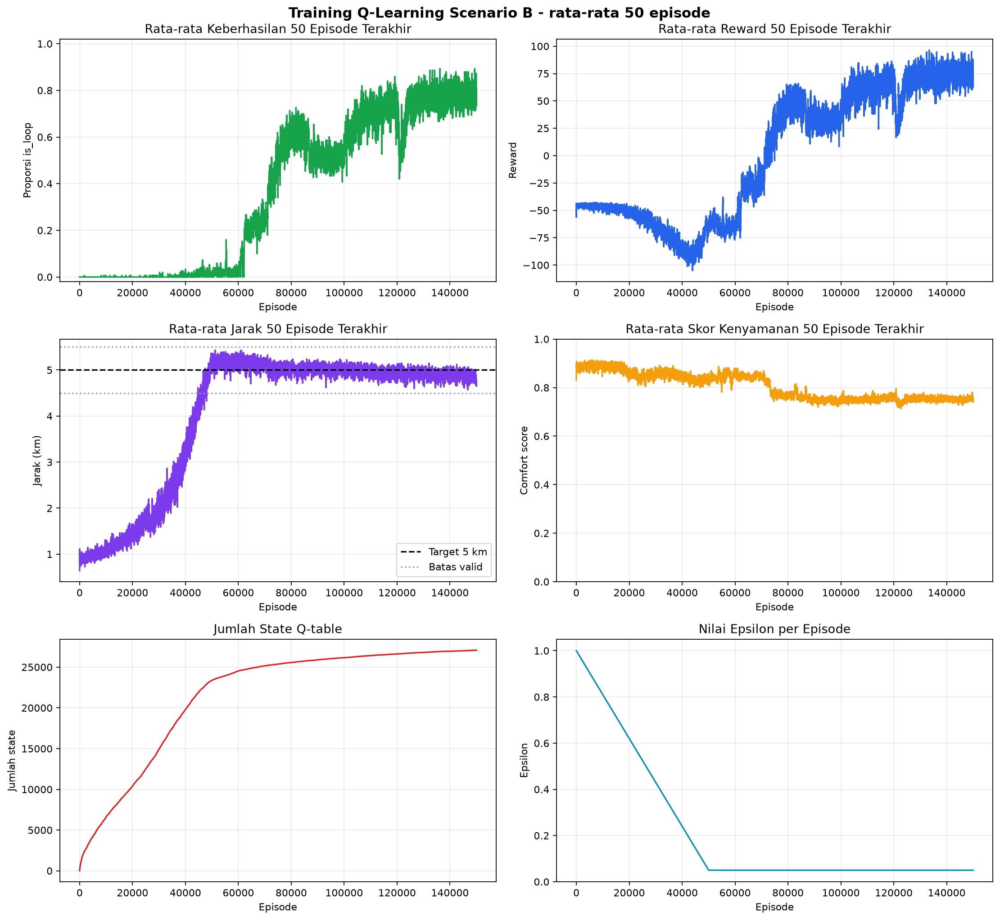

=== GRAFIK DIAGNOSIS ===


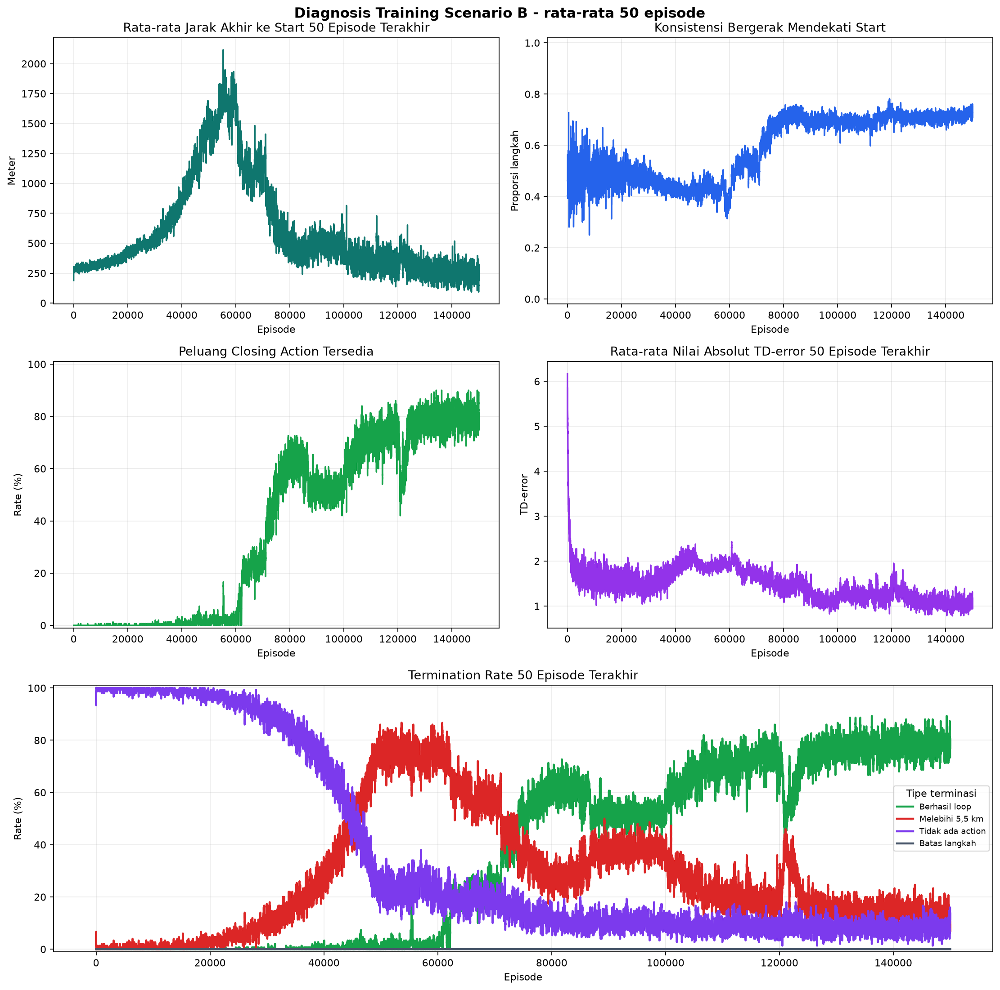

=== OVERLAP RUTE ===
overlap_ratio adalah proporsi lintasan ulang, disimpan 0–1; grafik dalam persen.


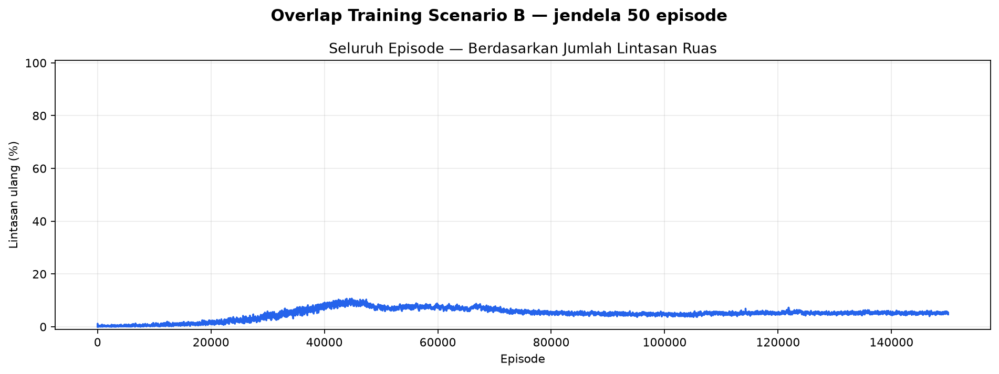

=== PERBANDINGAN URUTAN RUAS ===


,seed,kelompok_rute,is_loop,total_distance_m,absolute_distance_error_m,total_reward,mean_comfort,overlap_ratio,termination_reason
0,1362995605,Rute 1,True,5018.675589,18.675589,139.058311,0.700020,0.000000,success
1,467892251,Rute 2,True,4918.679878,81.320122,104.881520,0.641939,0.061224,success
2,173394943,Rute 3,True,4982.891184,17.108816,131.873188,0.922375,0.035088,success


Urutan rute unik: 3 dari 3 seed (termasuk rute gagal).
Kelompok sama = urutan edge identik; kelompok berbeda belum tentu jauh berbeda di peta.
=== SEED 1362995605 | Rute 1 ===


/Users/david/widya_kartika/uwika-ta-31123022-2026/.venv/lib/python3.13/site-packages/IPython/core/display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


=== SEED 467892251 | Rute 2 ===


=== SEED 173394943 | Rute 3 ===


In [79]:
if SEARCH_CONTEXT is None or (float(SEARCH_LAT), float(SEARCH_LON), DOWNLOAD_RADIUS_M) != SEARCH_CONTEXT[:3]:
    raise RuntimeError("Koordinat/radius berubah. Ulangi unduhan, peta dan training untuk titik baru.")
if TRAINING_CONTEXT != (SCENARIO, EPISODES, EPSILON_DECAY_EPISODES, RANDOM_SEEDS, MAX_WORKERS, SEARCH_CONTEXT):
    raise RuntimeError("Belum ada training selesai untuk pilihan saat ini. Jalankan training dahulu.")
core.display_saved_experiment_results(
    SCENARIO, result_subdir=RESULT_SUBDIR, show_map=False,
)

# Bandingkan rute tersimpan, tanpa melatih, mengunduh atau membaca Q-table lagi.
output_dir = core.RESULT_DIR / RESULT_SUBDIR
saved_point = json.loads((output_dir / "metadata_titik_start.json").read_text())
comparison = pd.read_csv(ARTIFACT_PATHS["evaluation"])
route_groups = {}
seed_groups = {}
for seed in saved_point["seeds"]:
    route = json.loads((output_dir / f"rute_evaluasi_scenario_{SCENARIO}_seed_{seed}.json").read_text())
    signature = tuple((edge["from_node"], edge["next_node"], edge["key"])
                      for edge in route["path_actions"])
    if signature not in route_groups:
        route_groups[signature] = f"Rute {len(route_groups) + 1}"
    seed_groups[seed] = route_groups[signature]
comparison["kelompok_rute"] = comparison["seed"].map(seed_groups)
comparison = comparison[["seed", "kelompok_rute", "is_loop", "total_distance_m",
                         "absolute_distance_error_m", "total_reward", "mean_comfort",
                         "overlap_ratio", "termination_reason"]]
comparison.to_csv(output_dir / "perbandingan_rute_seed.csv", index=False)
print("=== PERBANDINGAN URUTAN RUAS ===")
display(comparison)
print(f"Urutan rute unik: {len(route_groups)} dari {len(seed_groups)} seed (termasuk rute gagal).")
print("Kelompok sama = urutan edge identik; kelompok berbeda belum tentu jauh berbeda di peta.")
for seed in saved_point["seeds"]:
    print(f"=== SEED {seed} | {seed_groups[seed]} ===")
    # HTML ditanam langsung agar tampilan membaca file terbaru tanpa cache URL.
    map_html = (output_dir / f"peta_scenario_{SCENARIO}_seed_{seed}.html").read_text()
    display(HTML(f'<iframe srcdoc="{escape(map_html, quote=True)}" '
                 'style="width:100%;height:540px;border:0;"></iframe>'))
